# Stochastic simulation with bngsim

Gillespie's stochastic simulation algorithm (SSA), replicate ensembles, distributions, and network-free simulation
with NFsim.

The first part uses a minimal model of processive Ras activation in membrane corrals (Yonosh and Faeder, 2025). An
SOS molecule bound to the membrane activates many Ras molecules before it leaves, so the number of active Ras
clusters around values set by the number of bound SOS: the distribution has a peak for each SOS occupancy state. An
ODE simulation gives only the mean.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bionetgen_tools import BNGLSimulator, plot_ensemble, plot_distribution

ras = BNGLSimulator("../models/RasModel.bngl")
print("Observables:", ras.observables)
print({p: ras.get_parameter(p) for p in ras.parameters})

Observables: ['SOS_act', 'Ras_act']
{'k_bind': 0.005, 'k_unbind': 0.01, 'k_cat': 0.2, 'k_deact': 0.5, 'N_ras': 1000.0}


## One long SSA trajectory

10,000 s covers about 100 SOS binding and unbinding cycles; output every 0.1 s.

seed: 1


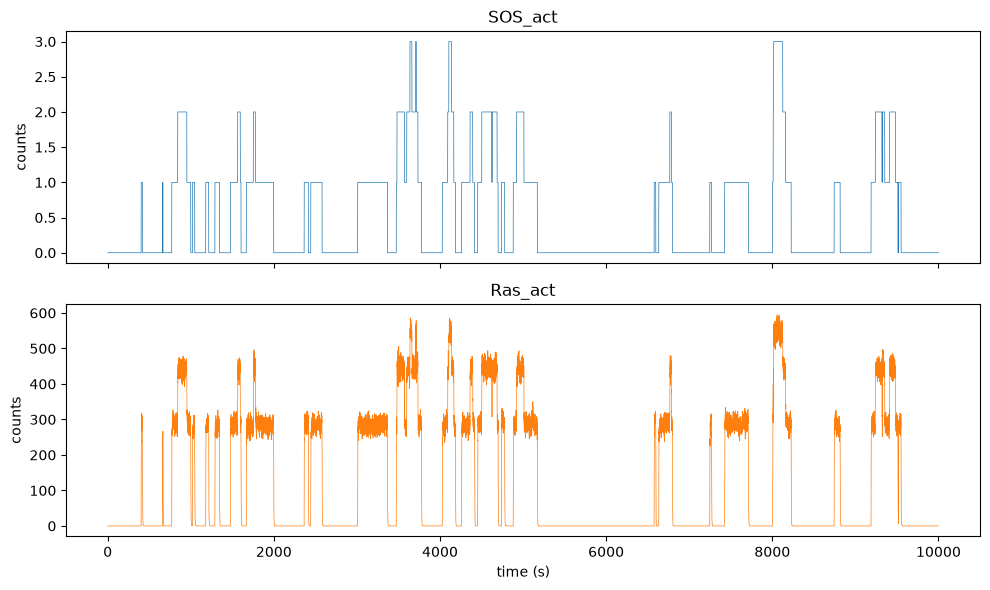

In [2]:
r = ras.simulate(t_end=10000, n_steps=100000, method="ssa", seed=1)
print("seed:", r.seed)

observables = r.observable_names
n_observables = len(observables)
default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
colors = [default_colors[i % len(default_colors)] for i in range(n_observables)]

fig, axes = plt.subplots(n_observables, 1, figsize=(10, 3 * n_observables), sharex=True)
for i, name in enumerate(observables):
    axes[i].plot(r["time"], r[name], color=colors[i], linewidth=0.5)
    axes[i].set_ylabel("counts")
    axes[i].set_title(name)
axes[-1].set_xlabel("time (s)")
plt.tight_layout()

## Distributions over time

Histograms of each observable over all output times (after the first 500 s, to skip the initial transient). The
Ras_act distribution has a peak for each SOS occupancy state.

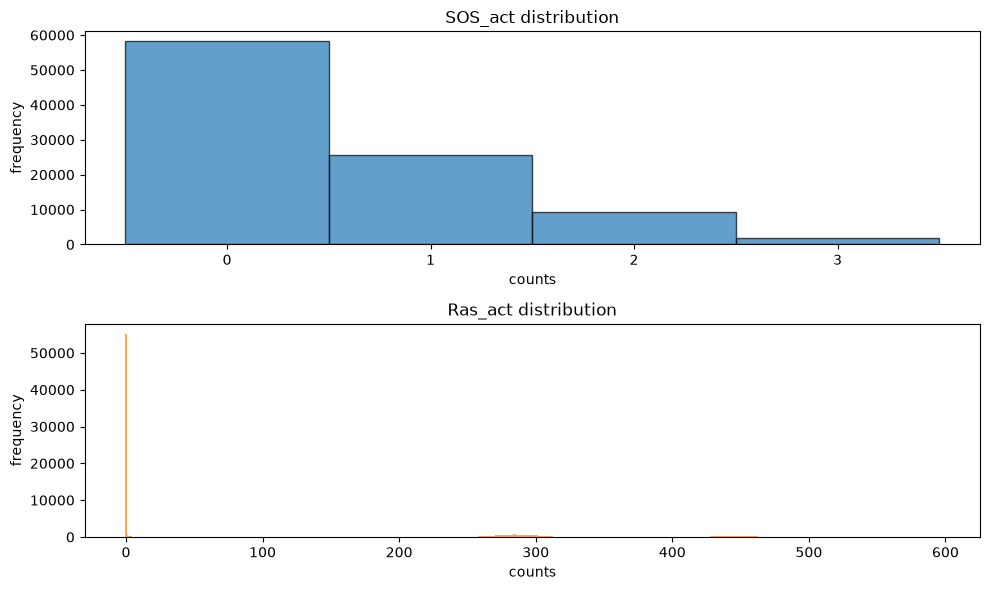

In [3]:
burn = r["time"] >= 500
fig, axes = plt.subplots(n_observables, 1, figsize=(10, 3 * n_observables))
for i, name in enumerate(observables):
    data = r[name][burn]
    lo, hi = int(np.floor(data.min())), int(np.ceil(data.max()))
    centers = np.arange(lo, hi + 1)
    edges = np.concatenate((centers - 0.5, [centers[-1] + 0.5]))
    axes[i].hist(data, bins=edges, color=colors[i], alpha=0.7, edgecolor="black" if len(centers) < 50 else None)
    axes[i].set_xlabel("counts")
    axes[i].set_ylabel("frequency")
    axes[i].set_title(f"{name} distribution")
    if len(centers) < 20:
        axes[i].set_xticks(centers)
plt.tight_layout()

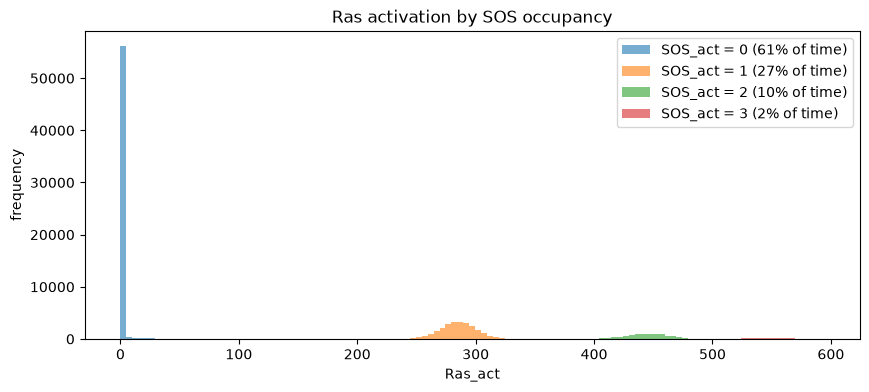

In [4]:
# Joint distribution: Ras_act grouped by the number of bound SOS
sos, ras_act = r["SOS_act"][burn], r["Ras_act"][burn]
plt.figure(figsize=(10, 4))
for n in range(int(sos.max()) + 1):
    sel = sos == n
    if sel.sum() > 100:
        plt.hist(ras_act[sel], bins=np.arange(-0.5, ras_act.max() + 1.5, 5), alpha=0.6,
                 label=f"SOS_act = {n} ({100 * sel.mean():.0f}% of time)")
plt.xlabel("Ras_act"); plt.ylabel("frequency"); plt.legend()
_ = plt.title("Ras activation by SOS occupancy")

## Replicate ensembles

`run_replicates` runs independent trajectories from the initial conditions; for SSA they run in parallel threads.
Each replicate's seed is recorded, so any one can be rerun exactly. Here the ensemble mean is compared with the ODE
solution. Mean SOS_act matches the ODE, but mean Ras_act falls well below it: Ras activation is a saturating
(concave) function of the number of bound SOS, so averaging over SOS fluctuations gives a lower mean than evaluating
at the mean SOS, which is what the ODE does.

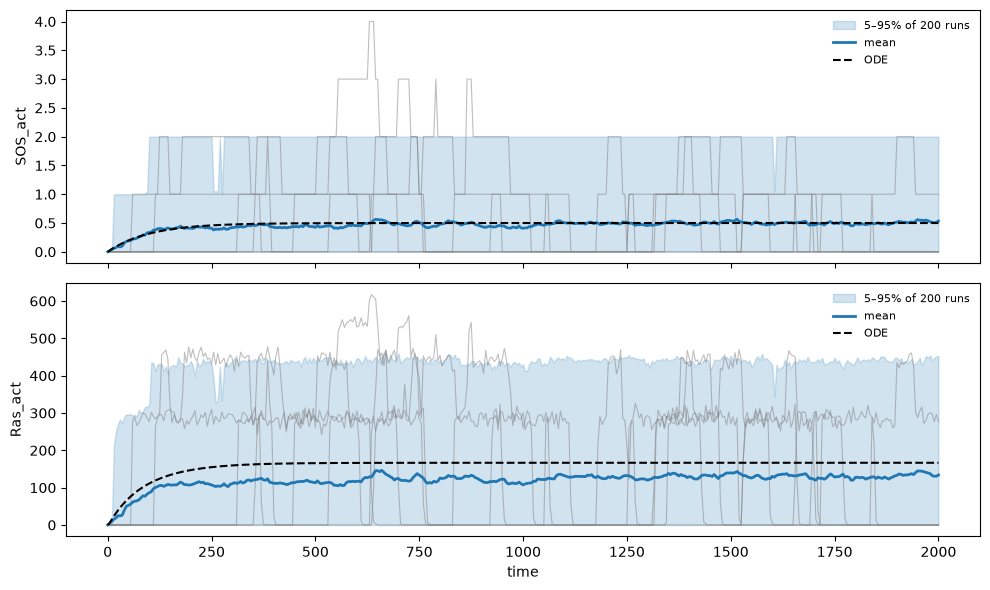

In [5]:
ens = ras.run_replicates(200, t_end=2000, n_steps=400, method="ssa", seed=7)
ode = ras.simulate(t_end=2000, n_steps=400, method="ode")
_ = plot_ensemble(ens, ode=ode)

Fano factor (variance/mean) at t = 2000: {'SOS_act': 0.97, 'Ras_act': 215.43}
Replicate 3 reproduced: True


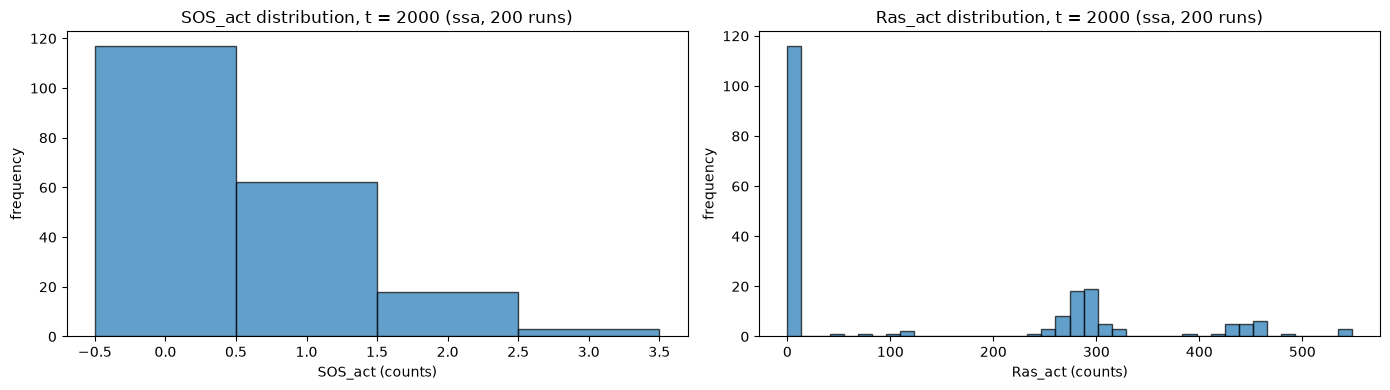

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_distribution(ens, "SOS_act", t=2000, ax=axes[0])
plot_distribution(ens, "Ras_act", t=2000, ax=axes[1], integer_bins=False, bins=40)
plt.tight_layout()

print("Fano factor (variance/mean) at t = 2000:",
      {n: round(float(ens.fano(n)[-1]), 2) for n in ens.observables})

# Rerun replicate 3 exactly from its seed
again = ras.simulate(t_end=2000, n_steps=400, method="ssa", seed=ens.seeds[3])
print("Replicate 3 reproduced:", np.array_equal(again["Ras_act"], ens["Ras_act"][3]))

## Network-free simulation: FcεRI with NFsim

`method="nf"` runs NFsim on the model's rules rather than its reaction network, which is necessary when the
network is too large to generate. For a model with a small network, like this one, NFsim and SSA sample the same
process, so their ensembles should agree. NFsim is slower here, so this uses only a few replicates.

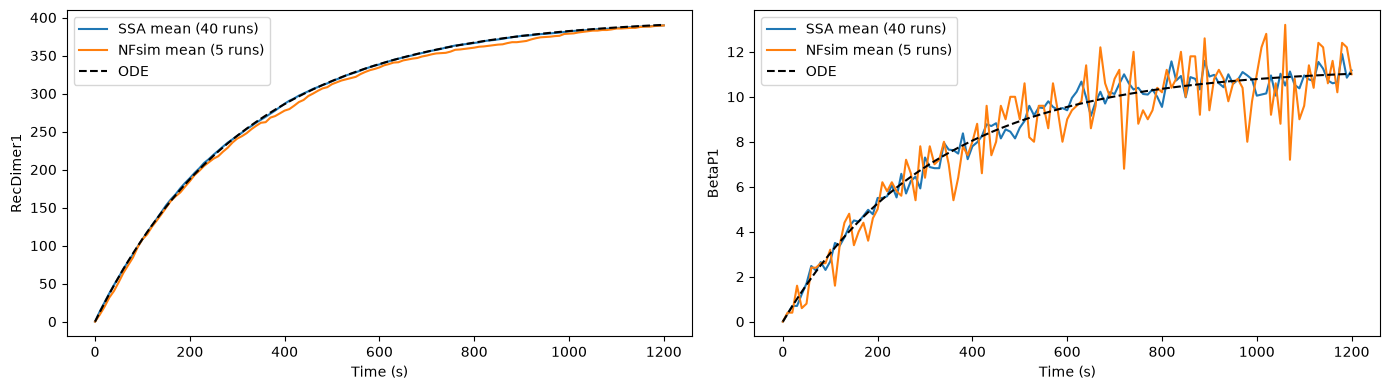

In [7]:
fceri = BNGLSimulator("../models/fceri_starter.bngl")
ens_ssa = fceri.run_replicates(40, t_end=1200, n_steps=120, method="ssa", seed=11)
ens_nf = fceri.run_replicates(5, t_end=1200, n_steps=120, method="nf", seed=11)
ode_f = fceri.simulate(t_end=1200, n_steps=120)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ["RecDimer1", "BetaP1"]):
    ax.plot(ens_ssa.time, ens_ssa.mean(name), label=f"SSA mean ({ens_ssa.n_replicates} runs)")
    ax.plot(ens_nf.time, ens_nf.mean(name), label=f"NFsim mean ({ens_nf.n_replicates} runs)")
    ax.plot(ode_f["time"], ode_f[name], "k--", label="ODE")
    ax.set_xlabel("Time (s)"); ax.set_ylabel(name); ax.legend()
plt.tight_layout()